# DR1 TP1: Velocidade e Qualidade com Estruturas de Dados e Algoritmos

**Aluno:** André Luis Becker  
**Professor:** Ian Monteiro Nunes  
**Instituto Infnet**, trimestre 26E4

## Apresentação

Implementei os 14 exercícios em Python 3.12, só com a biblioteca padrão, e rodei tudo no terminal do
Ubuntu (WSL2). Como na Aula 1, meço eficiência contando passos (comparações e trocas), não tempo. Os
dados aleatórios usam `random.seed(42)`, então os números se repetem em toda execução, e cada script
confere o próprio resultado com `[OK]` ou `[FALHA]`.

| Ex. | Tema | Resultado principal | Big O |
|---|---|---|---|
| 1 | Busca linear instrumentada | 1 comparação para o alvo na 1ª posição | O(N) |
| 2 | Ordenação das 13 cartas | é o Bubble Sort: 78 comparações no pior caso | O(N²) |
| 3 | Busca linear manual | 4 comparações para achar o 8 | O(N) |
| 4 | Busca binária manual | 1 comparação para achar o 8 | O(log N) |
| 5 | Maior número único | 1.000.000 → 1.625 passos com N = 1.000 | O(N²) → O(N) |
| 6 | Grãos de arroz | 1.000.000 de grãos → quadrado 21 | O(log Q) |
| 7 | Análise de `only_a_strings` | N iterações e no máximo 3N operações | O(N) |
| 8 | Cocktail Sort | 66 → 30 comparações com o menor valor no fim | O(N²) |
| 9 | Bubble Sort numérico | 9 listas de teste e 500 aleatórias corretas | O(N²) |
| 10 | Bubble Sort para strings | ordem lexicográfica x ordem alfabética | O(N²) |
| 11 | Bubble Sort instrumentado | 499.500 comparações com N = 1.000 | O(N²) |
| 12 | Bubble Sort otimizado | lista ordenada: 499.500 → 999 comparações | O(N) no melhor caso |
| 13 | Linear x binária | ordenar antes compensa a partir de 23 buscas | O(N) x O(log N) |
| 14 | Refatoração | 4 testes de equivalência passando | O(log N) e O(N²) |

Organizei o código em `src/` separando responsabilidades: `algoritmos/` tem as buscas e
ordenações, sem nenhuma entrada ou saída; `apresentacao/` formata o terminal e os gráficos; e cada
`exNN_*.py` só monta os dados do exercício, chama o núcleo e mostra o resultado. Assim cada
algoritmo existe uma vez só (o Bubble Sort, por exemplo, serve aos Exercícios 2, 8 a 14), e os 19
testes de `src/tests/` conferem o núcleo. Para rodar: `cd src` e `python3 ex01_busca_linear.py`.

In [1]:
import sys
sys.path.insert(0, "src")

## Exercício 1: Busca linear instrumentada

### Enunciado

> 1. Gere um array não ordenado com 10.000 números inteiros distintos.
> 2. Implemente uma função de busca linear em Python.
> 3. Instrumente o código para contar o número de comparações realizadas.
> 4. Execute a busca para um elemento presente na primeira posição do array.
> 5. Registre o número total de comparações.

### Teoria

Na Aula 1 vimos que o computador acessa qualquer posição do array em um passo, mas não sabe o que
tem em cada célula antes de olhar. Para buscar um valor ele precisa verificar célula por célula,
então a busca faz no máximo N passos. Na notação Big O (Aula 3) isso é O(N), tempo linear.

### Código

In [2]:
# src/algoritmos/busca.py
from algoritmos.metricas import Metricas
NAO_ENCONTRADO = -1


def busca_linear(seq, alvo, metricas=None, ao_comparar=None):
    metricas = metricas or Metricas()
    for indice, valor in enumerate(seq):
        if ao_comparar:
            ao_comparar(indice, valor)
        metricas.comparacoes += 1
        if valor == alvo:
            return indice
    return NAO_ENCONTRADO

In [3]:
import ex01_busca_linear
ex01_busca_linear.main()

Exercício 1: busca linear em 10.000 inteiros distintos (não ordenados)
──────────────────────────────────────────────────────────────────────
primeiros elementos: [83811, 14593, 3279, 97197, 36049, 32099, 29257, 18290] ...
[OK] 10.000 valores distintos
[OK] array não ordenado

alvo = arr[0] = 83811  ->  índice 0, comparações: 1
[OK] elemento na 1ª posição: 1 comparação (melhor caso)

Mesma busca para outras posições do alvo
────────────────────────────────────────
caso              índice  comparações
────────────────  ──────  ───────────
primeira posição       0            1
meio (N//2)         5000        5.001
última posição      9999       10.000
ausente               -1       10.000

Pior caso (alvo ausente) com N crescente
────────────────────────────────────────
N        comparações  razão
───────  ───────────  ─────
1.000          1.000    1·N
10.000        10.000    1·N
100.000      100.000    1·N


### Resposta

Gerei o array com `random.sample`, que sorteia 10.000 números entre 1 e 100.000 sem repetir, e o
script confere que eles são distintos e que o array não está ordenado. O contador soma 1 a cada
comparação `arr[i] == alvo`. Buscando o elemento da primeira posição (83811), a busca fez
**1 comparação**.

Esse é o melhor caso, então testei outras posições: o elemento do meio custou 5.001 comparações, e o
último ou um valor ausente custou 10.000. Com o alvo ausente e N = 1.000, 10.000 e 100.000, as
comparações foram exatamente N. O custo cresce na mesma proporção da entrada: **O(N)**. O gargalo é
que, num array sem ordem, uma comparação não elimina nenhuma outra posição.

## Exercício 2: Ordenação com cartas

### Enunciado

> 1. Elabore um algoritmo passo a passo para ordenar as 13 cartas de espadas conforme as restrições apresentadas.
> 2. Descreva claramente o estado inicial, as operações permitidas e o estado final.
> 3. Identifique qual algoritmo de ordenação clássico o procedimento mais se aproxima.
> 4. Justifique sua resposta com base nas operações realizadas.
> 5. Descreva qualitativamente o custo do algoritmo em termos de Big O.

### Teoria

Na Aula 3 o Bubble Sort foi apresentado assim: comparar dois vizinhos, trocar se estiverem fora de
ordem e repetir as passagens até não haver mais trocas. A cada passagem o maior valor restante
"sobe" até o fim. Nas Aulas 4 e 5 vimos o Selection Sort, que procura o menor e o leva para a frente,
e o Insertion Sort, que tira um valor da fila e desloca os outros para abrir espaço.

### Código

In [4]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def identidade(valor):
    return valor

def bubble_sort_com_parada(seq, chave=identidade, metricas=None, ao_fim_da_passagem=None):
    return _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas=True)

def _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas):
    metricas = metricas or Metricas()
    lista = list(seq)
    for ultimo in range(len(lista) - 1, 0, -1):     # a cada passagem, o maior restante vai para 'ultimo'
        trocou = _passagem(lista, range(ultimo), chave, metricas)
        if ao_fim_da_passagem:
            ao_fim_da_passagem(lista, metricas)
        if parar_sem_trocas and not trocou:
            break
    return lista

def _passagem(lista, posicoes, chave, metricas):
    metricas.passagens += 1
    trocou = False
    for i in posicoes:
        metricas.comparacoes += 1
        if chave(lista[i]) > chave(lista[i + 1]):
            lista[i], lista[i + 1] = lista[i + 1], lista[i]
            metricas.trocas += 1
            trocou = True
    return trocou

In [5]:
import ex02_cartas
ex02_cartas.main()

Exercício 2: 13 cartas de espadas, só trocas entre vizinhas
───────────────────────────────────────────────────────────
estado inicial:  8  7  3 10  K  6  Q  9  4  5  A  2  J 

passagem  fila após a passagem                    comparações  trocas
────────  ──────────────────────────────────────  ───────────  ──────
       1   7  3  8 10  6  Q  9  4  5  A  2  J  K           12      10
       2   3  7  8  6 10  9  4  5  A  2  J  Q  K           11       8
       3   3  7  6  8  9  4  5  A  2 10  J  Q  K           10       6
       4   3  6  7  8  4  5  A  2  9 10  J  Q  K            9       5
       5   3  6  7  4  5  A  2  8  9 10  J  Q  K            8       4
       6   3  6  4  5  A  2  7  8  9 10  J  Q  K            7       4
       7   3  4  5  A  2  6  7  8  9 10  J  Q  K            6       4
       8   3  4  A  2  5  6  7  8  9 10  J  Q  K            5       2
       9   3  A  2  4  5  6  7  8  9 10  J  Q  K            4       2
      10   A  2  3  4  5  6  7  8  9 10  J  Q  K     

### Resposta

**Restrições que considerei:** as cartas ficam enfileiradas na mesa, viradas para cima; só posso
segurar duas cartas vizinhas por vez, uma em cada mão; o único movimento é trocar essas duas de
lugar; e não há espaço extra na mesa.

| Estado inicial | Operações permitidas | Estado final |
|---|---|---|
| fila embaralhada (no exemplo: 8 7 3 10 K 6 Q 9 4 5 A 2 J) | comparar as duas cartas na mão, trocá-las, andar uma posição para a direita, voltar ao começo | A 2 3 4 5 6 7 8 9 10 J Q K |

O algoritmo:

1. Marco a última posição da fila como limite.
2. Pego a 1ª e a 2ª cartas.
3. Se a da mão esquerda for maior, troco as duas.
4. Ando uma posição para a direita e repito o passo 3 até chegar ao limite.
5. A maior carta que ainda estava fora do lugar chegou ao limite. Recuo o limite uma posição.
6. Se a passagem não teve nenhuma troca, a fila está ordenada e eu paro. Senão, volto ao passo 2.

Esse procedimento é o **Bubble Sort**, e por isso o script usa o `bubble_sort_com_parada` do
núcleo, só trocando a chave de comparação pelo valor da carta (A = 1, ..., K = 13). Só comparo e troco vizinhas, e cada passagem leva a maior
carta restante para o fim (na figura, o K chega ao fim na 1ª passagem, a Q na 2ª, e assim por
diante). Não é Selection Sort porque ele precisaria trocar cartas distantes, nem Insertion Sort,
porque ele precisaria tirar uma carta da fila e deslocar as outras.

Custo: no pior caso (ordem inversa) são 12 + 11 + ... + 1 = 78 comparações e 78 trocas, N(N−1)/2
com N = 13, então **O(N²)**. Com a fila já ordenada, uma passagem sem trocas basta: 12 comparações,
**O(N)**. No exemplo embaralhado foram 77 comparações e 47 trocas.

## Exercício 3: Busca linear (análise manual)

### Enunciado

> 1. Considere o array ordenado [2, 4, 6, 8, 10, 12, 13].
> 2. Simule manualmente a execução da busca linear pelo valor 8.
> 3. Conte o número de comparações realizadas.
> 4. Justifique o resultado obtido.
> 5. Relacione o número de passos ao tamanho do array.

### Teoria

Esse array é o mesmo do quiz da Aula 2. A busca linear começa no índice 0 e compara cada elemento
com o valor procurado até encontrá-lo ou chegar ao fim. Num array ordenado ela até pode parar antes
quando o valor não existe, mas o pior caso continua sendo N passos.

### Código

In [6]:
# src/ex03_busca_linear_manual.py
from algoritmos.busca import busca_linear
from algoritmos.metricas import medir
from apresentacao.terminal import ok, tabela, titulo
from dados import ARRAY_DA_AULA_2
ALVO = 8
AUSENTE = 7


def rastrear(seq, alvo):
    rastro = []
    indice, metricas = medir(busca_linear, seq, alvo, ao_comparar=lambda *par: rastro.append(par))
    return indice, metricas.comparacoes, rastro

In [7]:
import ex03_busca_linear_manual
ex03_busca_linear_manual.main()

Exercício 3: busca linear por 8 em [2, 4, 6, 8, 10, 12, 13]  (N = 7)
────────────────────────────────────────────────────────────────────
passo  índice  valor  comparação  igual?
─────  ──────  ─────  ──────────  ──────
    1       0      2   2 == 8?     não  
    2       1      4   4 == 8?     não  
    3       2      6   6 == 8?     não  
    4       3      8   8 == 8?     sim  

encontrado no índice 3 após 4 comparações
[OK] comparações = posição do alvo + 1 = 4

Passos da busca linear para cada alvo possível
──────────────────────────────────────────────
alvo  índice  comparações
────  ──────  ───────────
2          0            1
4          1            2
6          2            3
8          3            4
10         4            5
12         5            6
13         6            7
7         -1            7
pior caso (último ou ausente): N = 7 comparações  ->  O(N)


### Resposta

| Passo | Índice | Valor | 8 é igual? |
|---|---|---|---|
| 1 | 0 | 2 | não |
| 2 | 1 | 4 | não |
| 3 | 2 | 6 | não |
| 4 | 3 | 8 | **sim** |

Foram **4 comparações**. O 8 está no índice 3, e antes dele a busca precisa descartar o 2, o 4 e o 6,
uma comparação para cada. Um valor no índice i custa i + 1 comparações. Com N = 7, o melhor caso é 1
comparação e o pior é 7 (último elemento ou valor ausente). O número de passos cresce junto com o
tamanho do array: **O(N)**.

## Exercício 4: Busca binária (análise manual)

### Enunciado

> 1. Utilize o mesmo array do Exercício 3.
> 2. Simule manualmente a execução da busca binária pelo valor 8.
> 3. Conte o número de comparações realizadas.
> 4. Compare o resultado com a busca linear.
> 5. Relacione a diferença observada à notação Big O.

### Teoria

A busca binária (Aula 2) só funciona em array ordenado. Ela olha o elemento do meio e, conforme o
valor procurado seja menor ou maior, descarta metade do array. Como cada passo corta o problema pela
metade, o número máximo de passos é log₂N arredondado para baixo, mais 1. Na Big O, O(log N) (Aula 3).

### Código

In [8]:
# src/algoritmos/busca.py
from algoritmos.metricas import Metricas
NAO_ENCONTRADO = -1


def busca_binaria(seq_ordenada, alvo, metricas=None, ao_inspecionar=None):
    metricas = metricas or Metricas()
    inicio, fim = 0, len(seq_ordenada) - 1
    while inicio <= fim:
        meio = (inicio + fim) // 2
        metricas.iteracoes += 1
        if ao_inspecionar:
            ao_inspecionar(inicio, fim, meio)

        metricas.comparacoes += 1
        if seq_ordenada[meio] == alvo:
            return meio

        metricas.comparacoes += 1
        if alvo < seq_ordenada[meio]:
            fim = meio - 1          # o alvo só pode estar à esquerda do meio
        else:
            inicio = meio + 1       # o alvo só pode estar à direita do meio
    return NAO_ENCONTRADO

In [9]:
import ex04_busca_binaria_manual
ex04_busca_binaria_manual.main()

Exercício 4: busca binária por 8 em [2, 4, 6, 8, 10, 12, 13]  (N = 7)
─────────────────────────────────────────────────────────────────────
passo  intervalo  meio  valor  decisão
─────  ─────────  ────  ─────  ───────
    1   [0..6]       3      8  achou  

encontrado no índice 3 após 1 comparação(ões)
[OK] 8 é exatamente o elemento central: 1 comparação

Linear x binária para cada alvo possível
────────────────────────────────────────
alvo  linear  binária
────  ──────  ───────
2          1        3
4          2        2
6          3        3
8          4        1
10         5        3
12         6        2
13         7        3
7          7        3
pior caso: linear = N = 7; binária = int(log2 N) + 1 = 3
[OK] pior caso da binária confere com log2 N

Pior caso com N crescente (alvo ausente, maior que todos)
─────────────────────────────────────────────────────────
N          linear O(N)  binária O(log N)
─────────  ───────────  ────────────────
7                    7                 

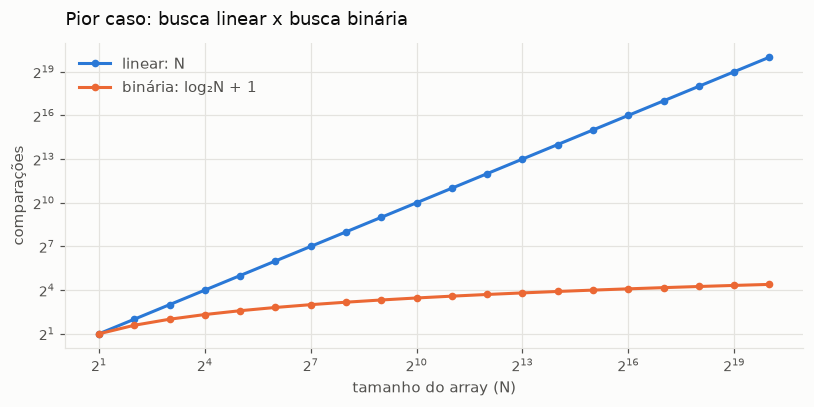

In [10]:
from apresentacao.graficos import novo, linha, mostrar, AZUL, LARANJA
from algoritmos.busca import busca_binaria
from algoritmos.metricas import medir

tamanhos = [2 ** k for k in range(1, 21)]
binaria = [medir(busca_binaria, range(n), n)[1].iteracoes for n in tamanhos]

fig, ax = novo("Pior caso: busca linear x busca binária", "tamanho do array (N)", "comparações")
linha(ax, tamanhos, tamanhos, AZUL, "linear: N")
linha(ax, tamanhos, binaria, LARANJA, "binária: log₂N + 1")
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
mostrar(fig, ax, "ex04_linear_x_binaria")

### Resposta

| Passo | Intervalo | Meio | Valor | Decisão |
|---|---|---|---|---|
| 1 | [0..6] | (0 + 6) // 2 = 3 | 8 | **achou** |

Achei na primeira tentativa, com **1 comparação**, contra 4 da busca linear. Esse caso foi favorável,
porque o 8 é exatamente o elemento do meio, então o script testa todos os valores do array: a
binária nunca passou de 3 comparações, e a linear chegou a 7.

A diferença aumenta com N (gráfico acima, em escala logarítmica): para 1.000.000 de elementos, a
linear pode precisar de 1.000.000 de comparações e a binária de 20. Dobrar o array acrescenta só um
passo na binária. A linear é **O(N)** e a binária é **O(log N)**, desde que o array esteja ordenado.

## Exercício 5: Otimização de O(N²) para O(N)

### Enunciado

> 1. Analise a função fornecida para encontrar o maior número único.
> 2. Identifique o motivo de sua complexidade O(N²).
> 3. Reescreva a função para que opere em O(N).
> 4. Explique a estratégia utilizada para reduzir a complexidade.
> 5. Justifique a nova complexidade usando Big O.

### Teoria

Na Aula 4 vimos que um laço dentro de outro laço sobre os mesmos dados costuma indicar O(N²). O
exemplo da aula (verificar valores duplicados) foi resolvido em O(N) trocando o laço interno por uma
estrutura auxiliar, com o custo de usar mais memória.

### Código

In [11]:
# src/algoritmos/unicos.py
from algoritmos.metricas import Metricas


def maior_unico(arr, metricas=None):
    metricas = metricas or Metricas()
    ocorrencias = {}
    for valor in arr:
        metricas.iteracoes += 1
        ocorrencias[valor] = ocorrencias.get(valor, 0) + 1

    maior = None
    for valor, quantidade in ocorrencias.items():
        metricas.iteracoes += 1
        if quantidade == 1 and (maior is None or valor > maior):
            maior = valor
    return maior

In [12]:
import ex05_maior_unico
ex05_maior_unico.main()

Exercício 5: maior número único: original O(N²) x otimizada O(N)
────────────────────────────────────────────────────────────────
entrada                      original  otimizada
───────────────────────────  ────────  ─────────
[5, 7, 3, 9, 4, 9, 8, 3, 1]         8          8
[2, 2, 3, 3]                     None       None
[]                               None       None
[42]                               42         42
[-5, -1, -1, -7]                   -5         -5
[10, 10, 9]                         9          9
[OK] mesmo resultado nos 56 casos (6 acima + 50 aleatórios com N = 200)

Passos executados em função de N
────────────────────────────────


N      original (N²)  otimizada (≤ 2N)  redução
─────  ─────────────  ────────────────  ───────
10               100                17       6x
100           10.000               158      63x
1.000      1.000.000             1.625     615x
5.000     25.000.000             8.143    3070x


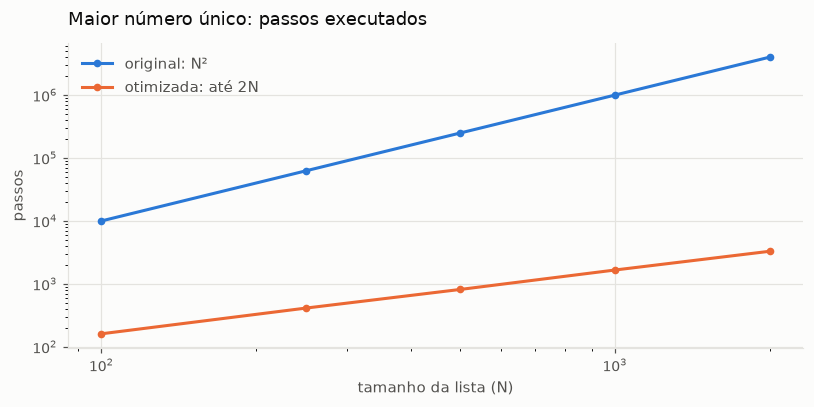

In [13]:
import random
from apresentacao.graficos import novo, linha, mostrar, AZUL, LARANJA
from algoritmos.metricas import medir
from algoritmos.unicos import maior_unico, maior_unico_quadratico

random.seed(42)
tamanhos = [100, 250, 500, 1000, 2000]
listas = [[random.randint(0, n) for _ in range(n)] for n in tamanhos]
original = [medir(maior_unico_quadratico, lista)[1].iteracoes for lista in listas]
otimizada = [medir(maior_unico, lista)[1].iteracoes for lista in listas]

fig, ax = novo("Maior número único: passos executados", "tamanho da lista (N)", "passos")
linha(ax, tamanhos, original, AZUL, "original: N²")
linha(ax, tamanhos, otimizada, LARANJA, "otimizada: até 2N")
ax.set_xscale("log")
ax.set_yscale("log")
mostrar(fig, ax, "ex05_original_x_otimizada")

### Resposta

**Por que é O(N²):** a função original tem um `for j` dentro do `for i`. Para cada um dos N elementos
ela percorre o array inteiro de novo só para contar quantas vezes aquele valor aparece. São N × N
comparações em qualquer entrada, porque o laço interno nunca para antes.

**Estratégia:** faço uma passada preenchendo um dicionário `valor → quantidade` e depois uma passada
pelos valores do dicionário, guardando o maior que tem quantidade 1. As duas passadas são uma depois
da outra, não uma dentro da outra, e inserir ou consultar no dicionário custa O(1) em média, porque
ele é uma tabela hash. O total fica em no máximo 2N passos: **O(N)**.

As duas versões deram o mesmo resultado nos 56 casos de teste. Com N = 1.000, a original fez
1.000.000 de passos e a nova, 1.625; com N = 5.000, 25.000.000 contra 8.143. O preço é a memória
extra do dicionário, como na Aula 4.

## Exercício 6: Tabuleiro de xadrez e grãos de arroz

### Enunciado

> 1. Implemente uma função em Python que receba como parâmetro um número inteiro positivo qtd_graos.
> 2. Calcule qual é o menor índice de quadrado do tabuleiro em que a quantidade de grãos acumulada no próprio quadrado é maior ou igual a qtd_graos.
> 3. Caso a quantidade informada ultrapasse o total de grãos do tabuleiro (64 quadrados), a função deve retornar uma mensagem indicando que o valor excede o limite do tabuleiro.
> 4. Teste a função com valores pequenos (1, 2, 4, 8), intermediários (1.000, 1.000.000) e um valor maior que o total de grãos possíveis no tabuleiro.
> 5. Descreva a complexidade temporal da solução implementada utilizando Notação Big O, justificando com base no número de iterações realizadas.
>
> O quadrado n tem 2^(n-1) grãos. Não vale fórmula pronta: a solução deve ser iterativa ou recursiva.

### Teoria

Na Aula 2 vimos que dobrar uma quantidade P vezes é multiplicar por 2^P, e que a operação inversa da
exponencial é o logaritmo: se N = 2^P, então P = log₂N. É a mesma ideia que deixa a busca binária
rápida, só que aqui ao contrário: os grãos dobram a cada quadrado.

### Código

In [14]:
# src/algoritmos/tabuleiro.py
from algoritmos.metricas import Metricas
QUADRADOS = 64
MAX_POR_QUADRADO = 2 ** (QUADRADOS - 1)     # grãos no quadrado 64
TOTAL_DO_TABULEIRO = 2 ** QUADRADOS - 1     # soma dos 64 quadrados
MENSAGEM_LIMITE = "valor excede o limite do tabuleiro"


def menor_quadrado(qtd_graos, metricas=None):
    if not isinstance(qtd_graos, int) or qtd_graos <= 0:
        raise ValueError("qtd_graos deve ser um inteiro positivo")
    metricas = metricas or Metricas()

    graos = 1
    for quadrado in range(1, QUADRADOS + 1):
        metricas.iteracoes += 1
        if graos >= qtd_graos:
            return quadrado
        graos *= 2                          # o próximo quadrado tem o dobro
    return MENSAGEM_LIMITE

In [15]:
import ex06_graos_arroz
ex06_graos_arroz.main()

Exercício 6: menor quadrado com grãos >= qtd_graos
──────────────────────────────────────────────────
faixa                                  qtd_graos  quadrado  iterações
────────────────────  ──────────────────────────  ────────  ─────────
pequeno                                        1         1          1
pequeno                                        2         2          2
pequeno                                        4         3          3
pequeno                                        8         4          4
pequeno                                        5         4          4
intermediário                              1.000        11         11
intermediário                          1.000.000        21         21
limite                 9.223.372.036.854.775.808        64         64
acima do quadrado 64   9.223.372.036.854.775.809  mensagem         64
acima do total        18.446.744.073.709.551.616  mensagem         64
[OK] todos os resultados conferem com o esperado

mensagem

### Resposta

A função começa no quadrado 1 com 1 grão. A cada iteração confere se os grãos daquele quadrado
atendem à quantidade pedida e, se não, dobra os grãos e passa para o próximo. Ela devolve o quadrado
e o número de iterações. Entradas que não são inteiros positivos geram `ValueError`.

| qtd_graos | 1 | 2 | 4 | 8 | 1.000 | 1.000.000 | 2^64 |
|---|---|---|---|---|---|---|---|
| quadrado | 1 | 2 | 3 | 4 | 11 | 21 | excede o limite |

O maior valor que cabe num quadrado é o do quadrado 64, 2^63 grãos, e o total do tabuleiro é
2^64 − 1. Testei 2^64, que passa do total como o enunciado pede, e também 2^63 + 1, que não cabe em
nenhum quadrado mesmo sendo menor que o total. Nos dois casos a função devolve a mensagem de limite.

O número de iterações é o índice do quadrado encontrado, log₂(qtd_graos) arredondado para cima, mais
1, porque os grãos dobram a cada volta. A solução é **O(log Q)**, com Q = qtd_graos, e nunca passa de
64 iterações. Somar grão por grão seria O(Q), algo como 9 × 10¹⁸ iterações.

## Exercício 7: Notação Big O (análise de código)

### Enunciado

> 1. Identifique quantas vezes o laço for é executado em função de N.
> 2. Descreva as operações realizadas a cada iteração do laço.
> 3. Determine o custo total da função em função do tamanho do array de entrada.
> 4. Expresse a complexidade temporal do algoritmo utilizando Notação Big O.
> 5. Justifique tecnicamente sua resposta, relacionando a estrutura do código ao crescimento assintótico.
>
> Premissas: o array tem N elementos, as strings têm tamanho médio constante e `len(s)`, `s[0] == "a"` e `append` custam O(1).

### Teoria

Na Aula 3 o exemplo de imprimir todos os itens de uma lista é O(N): um laço que passa uma vez por
cada elemento. Na Aula 4 vimos que constantes são ignoradas, então 3N passos ainda é O(N).

### Código

In [16]:
def only_a_strings(strings):
    result = []                              # 1 vez
    for s in strings:                        # N vezes
        if len(s) > 0 and s[0] == "a":       # até 2 operações O(1)
            result.append(s)                 # até 1 operação O(1)
    return result                            # 1 vez

In [17]:
import ex07_only_a_strings
ex07_only_a_strings.main()

Exercício 7: only_a_strings: o laço executa uma vez por elemento
────────────────────────────────────────────────────────────────
entrada: ['abacate', 'banana', '', 'amora', 'Ameixa', 'acerola', 'uva']
saída:   ['abacate', 'amora', 'acerola']
[OK] cópia instrumentada devolve o mesmo resultado

Iterações e operações O(1) em função de N
─────────────────────────────────────────
N        iterações  operações (aleatória)  operações (pior caso)  pior/N
───────  ─────────  ─────────────────────  ─────────────────────  ──────
10              10                     24                     30     3·N
100            100                    233                    300     3·N
1.000        1.000                  2.269                  3.000     3·N
10.000      10.000                 22.850                 30.000     3·N
100.000    100.000                228.222                300.000     3·N
iterações = N em qualquer entrada; operações <= 3N  ->  T(N) = O(N)


### Resposta

1. O laço roda exatamente **N vezes**, uma por elemento. Não tem `break` nem `return` dentro dele.
2. Em cada volta: `len(s) > 0` sempre; `s[0] == "a"` só se a string não for vazia, porque o `and`
   para no primeiro teste falso; e `append` só se os dois testes derem verdadeiro. São de 1 a 3
   operações O(1).
3. Somando a criação da lista e o `return`: T(N) = 3N + 2 no pior caso (todas começam com "a") e
   N + 2 no melhor (todas vazias).
4. **O(N)**.
5. É um único laço, sem outro dentro, e o corpo tem custo constante porque as strings não crescem
   com N. Tirando a constante 3 e o termo 2, sobra N: dobrar a quantidade de strings dobra o trabalho.

Para conferir, rodei uma cópia da função com contadores: de N = 10 a 100.000 as iterações foram
exatamente N e, no pior caso, as operações foram exatamente 3N.

## Exercício 8: Bubble Sort bidirecional (Cocktail Sort)

### Enunciado

> 1. Modifique o Bubble Sort para torná-lo bidirecional.
> 2. Utilize dois índices externos, esquerdo e direito.
> 3. Garanta que o maior elemento vá para a direita e o menor para a esquerda.
> 4. Teste o algoritmo com diferentes arrays.
> 5. Compare conceitualmente com o Bubble Sort tradicional.

### Teoria

O Bubble Sort da Aula 3 só anda da esquerda para a direita. Um valor grande no começo chega ao fim
numa passagem só, mas um valor pequeno no fim anda apenas uma posição para a esquerda por passagem.
A Aula 5 mostrou que vale analisar também o melhor caso e o caso médio, não só o pior.

### Código

In [18]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def identidade(valor):
    return valor

def cocktail_sort(seq, chave=identidade, metricas=None):
    metricas = metricas or Metricas()
    lista = list(seq)
    esquerdo, direito = 0, len(lista) - 1
    while esquerdo < direito:
        if not _passagem(lista, range(esquerdo, direito), chave, metricas):
            break
        direito -= 1
        if not _passagem(lista, range(direito - 1, esquerdo - 1, -1), chave, metricas):
            break
        esquerdo += 1
    return lista

In [19]:
import ex08_cocktail_sort
ex08_cocktail_sort.main()

Exercício 8: Cocktail Sort: resultados
──────────────────────────────────────
aleatória                 [82 15 4 95 36 32 29 18 14 87 70 12] -> [4 12 14 15 18 29 32 36 70 82 87 95]
já ordenada               [1 2 3 4 5 6 7 8 9 10 11 12]         -> [1 2 3 4 5 6 7 8 9 10 11 12]
ordem inversa             [12 11 10 9 8 7 6 5 4 3 2 1]         -> [1 2 3 4 5 6 7 8 9 10 11 12]
com repetidos             [5 1 4 1 5 9 2 6 5 3]                -> [1 1 2 3 4 5 5 5 6 9]
tartaruga (menor no fim)  [2 3 4 5 6 7 8 9 10 11 12 1]         -> [1 2 3 4 5 6 7 8 9 10 11 12]
coelho (maior no início)  [12 1 2 3 4 5 6 7 8 9 10 11]         -> [1 2 3 4 5 6 7 8 9 10 11 12]
vazia                     []                                   -> []
um elemento               [7]                                  -> [7]
[OK] todas as saídas ordenadas e com os mesmos elementos da entrada

Bubble tradicional x bidirecional (ambos com parada antecipada)
───────────────────────────────────────────────────────────────
entrada        

### Resposta

Os índices `esquerdo` e `direito` marcam a parte que ainda não está ordenada. Na ida, o maior valor
vai até `direito` e `direito` diminui; na volta, o menor valor vai até `esquerdo` e `esquerdo`
aumenta. Se uma passagem termina sem trocas, o algoritmo para. As 8 listas de teste saíram ordenadas.

| Entrada | Bubble (passagens / comparações) | Cocktail (passagens / comparações) |
|---|---|---|
| menor valor no fim | 11 / 66 | **3 / 30** |
| aleatória | 11 / 66 | 8 / 60 |
| ordem inversa | 11 / 66 | 12 / 66 |
| já ordenada | 1 / 11 | 1 / 11 |

A diferença aparece quando o menor valor está no fim: no Bubble Sort ele leva 11 passagens para
chegar ao começo, e no Cocktail Sort chega em uma volta. Na ordem inversa não há ganho. Os dois
continuam **O(N²)** no pior caso e no caso médio, e **O(N)** com a lista já ordenada: o ganho do
Cocktail é de constante e depende da entrada.

## Exercício 9: Bubble Sort numérico

### Enunciado

> 1. Implemente o Bubble Sort em Python.
> 2. Ordene uma lista de números em ordem crescente.
> 3. Teste com listas já ordenadas e desordenadas.
> 4. Verifique a corretude da saída.
> 5. Registre evidências de execução.

### Teoria

Implementei a versão da Aula 3: cada passagem compara vizinhos e troca os que estão fora de ordem, e
o maior valor restante vai para o fim. Como o fim já fica certo, a passagem seguinte vai uma posição
a menos. São (N−1) + (N−2) + ... + 1 = N(N−1)/2 comparações, O(N²).

### Código

In [20]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def identidade(valor):
    return valor

def bubble_sort(seq, chave=identidade, metricas=None, ao_fim_da_passagem=None):
    return _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas=False)

def _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas):
    metricas = metricas or Metricas()
    lista = list(seq)
    for ultimo in range(len(lista) - 1, 0, -1):     # a cada passagem, o maior restante vai para 'ultimo'
        trocou = _passagem(lista, range(ultimo), chave, metricas)
        if ao_fim_da_passagem:
            ao_fim_da_passagem(lista, metricas)
        if parar_sem_trocas and not trocou:
            break
    return lista

def _passagem(lista, posicoes, chave, metricas):
    metricas.passagens += 1
    trocou = False
    for i in posicoes:
        metricas.comparacoes += 1
        if chave(lista[i]) > chave(lista[i + 1]):
            lista[i], lista[i + 1] = lista[i + 1], lista[i]
            metricas.trocas += 1
            trocou = True
    return trocou

In [21]:
import ex09_bubble_sort
ex09_bubble_sort.main()

Exercício 9: Bubble Sort numérico
─────────────────────────────────
desordenada     [64 34 25 12 22 11 90]                         -> [11 12 22 25 34 64 90]
já ordenada     [1 2 3 4 5 6 7]                                -> [1 2 3 4 5 6 7]
ordem inversa   [9 8 7 6 5 4 3 2 1]                            -> [1 2 3 4 5 6 7 8 9]
com repetidos   [3 1 2 3 1 2]                                  -> [1 1 2 2 3 3]
negativos       [0 -3 5 -1 -8 2]                               -> [-8 -3 -1 0 2 5]
float e int     [2.5 -1 3.14 0 2]                              -> [-1 0 2 2.5 3.14]
vazia           []                                             -> []
um elemento     [42]                                           -> [42]
aleatória N=12  [81 14 3 94 35 31 28 17 13 86 69 11]           -> [3 11 13 14 17 28 31 35 69 81 86 94]

[OK] saídas em ordem crescente, mesmos elementos, entrada original intacta


[OK] 500 listas aleatórias (N de 0 a 60) iguais ao sorted() do Python


### Resposta

A função trabalha numa cópia, para não alterar a lista original. Testei 9 listas: desordenada, já
ordenada, inversa, com repetidos, com negativos, misturando `int` e `float`, vazia, com um elemento e
uma aleatória. Para cada uma o script confere se a saída está em ordem crescente, se tem exatamente
os mesmos elementos da entrada e se a entrada continuou igual. Também comparei com o `sorted()` do
Python em 500 listas aleatórias, só como referência. Tudo deu `[OK]`.

Essa versão faz N(N−1)/2 comparações mesmo com a lista já ordenada, por isso é **O(N²)** em qualquer
caso. A correção disso é o Exercício 12.

## Exercício 10: Bubble Sort para strings

### Enunciado

> 1. Modifique o Bubble Sort para ordenar strings.
> 2. Ordene listas de palavras em ordem alfabética.
> 3. Teste com diferentes conjuntos de strings.
> 4. Valide os resultados.
> 5. Documente o comportamento observado.

### Teoria

Em Python, comparar duas strings com `>` é comparar letra por letra pelo código Unicode (ordem
lexicográfica). Isso é parecido com a ordem alfabética, mas não igual: maiúsculas e letras com
acento têm códigos diferentes das minúsculas sem acento.

### Código

In [22]:
# src/algoritmos/texto.py
import unicodedata


def chave_alfabetica(palavra):
    decomposta = unicodedata.normalize("NFD", palavra.casefold())
    return "".join(letra for letra in decomposta if unicodedata.category(letra) != "Mn")

In [23]:
import ex10_bubble_strings
ex10_bubble_strings.main()

Exercício 10: Bubble Sort para strings
──────────────────────────────────────
1) minúsculas sem acento
  entrada: ['uva', 'banana', 'abacate', 'manga', 'caju', 'laranja']
  saída:   ['abacate', 'banana', 'caju', 'laranja', 'manga', 'uva']
2) prefixos: o menor prefixo vem antes
  entrada: ['casamento', 'casa', 'cas', 'casarão', 'caso']
  saída:   ['cas', 'casa', 'casamento', 'casarão', 'caso']
3) maiúsculas/minúsculas, ordem lexicográfica pura (código Unicode)
  entrada: ['banana', 'Zebra', 'abacate', 'Maçã']
  saída:   ['Maçã', 'Zebra', 'abacate', 'banana']
4) mesmo conjunto com chave_alfabetica, ordem de dicionário
  entrada: ['banana', 'Zebra', 'abacate', 'Maçã']
  saída:   ['abacate', 'banana', 'Maçã', 'Zebra']
5) acentos, ordem lexicográfica pura
  entrada: ['ética', 'ervilha', 'zebra', 'ábaco', 'abelha']
  saída:   ['abelha', 'ervilha', 'zebra', 'ábaco', 'ética']
6) acentos com chave_alfabetica
  entrada: ['ética', 'ervilha', 'zebra', 'ábaco', 'abelha']
  saída:   ['ábaco', 'abelh

### Resposta

O algoritmo é o mesmo `bubble_sort` do Exercício 9; a única mudança é a função `chave` usada na
comparação. Sem chave, a ordem é a lexicográfica do Python. Com `chave_alfabetica`, que deixa tudo
minúsculo e tira os acentos, a ordem fica alfabética como num dicionário.

| Caso testado | O que aconteceu | Por quê |
|---|---|---|
| minúsculas sem acento | ordem alfabética normal | os códigos seguem o alfabeto |
| prefixos | cas < casa < casamento | a palavra menor vem primeiro |
| maiúsculas | "Maçã" e "Zebra" antes de "abacate" | 'Z' = 90 < 'a' = 97 |
| acentos | "ábaco" e "ética" depois de "zebra" | 'á' = 225 > 'z' = 122 |
| números como texto | "10" antes de "9" | compara dígito a dígito |
| com `chave_alfabetica` | maiúsculas e acentos no lugar certo | compara sem caixa e sem acento |

Validei cada saída como no Exercício 9, usando o mesmo critério de comparação. A complexidade
continua **O(N²)**; para strings longas cada comparação custa até o tamanho L da palavra, mas aqui as
palavras são curtas e L é constante.

## Exercício 11: Instrumentação do Bubble Sort

### Enunciado

> 1. Instrumente o Bubble Sort para contar comparações.
> 2. Conte também o número de trocas.
> 3. Execute o algoritmo para diferentes tamanhos de entrada.
> 4. Registre os resultados.
> 5. Analise o crescimento observado.

### Teoria

Na Aula 3 a análise do Bubble Sort deu (N² − N)/2 comparações e, no pior caso, o mesmo número de
trocas, total N² − N passos. Na Aula 5 vimos que, numa lista aleatória, cada par tem 50% de chance
de estar invertido, então em média são cerca de N(N−1)/4 inversões.

### Código

In [24]:
# src/algoritmos/metricas.py
from dataclasses import dataclass


class Metricas:
    comparacoes: int = 0
    trocas: int = 0
    passagens: int = 0
    iteracoes: int = 0

def medir(algoritmo, *args, **kwargs):
    metricas = Metricas()
    return algoritmo(*args, metricas=metricas, **kwargs), metricas

In [25]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def _passagem(lista, posicoes, chave, metricas):
    metricas.passagens += 1
    trocou = False
    for i in posicoes:
        metricas.comparacoes += 1
        if chave(lista[i]) > chave(lista[i + 1]):
            lista[i], lista[i + 1] = lista[i + 1], lista[i]
            metricas.trocas += 1
            trocou = True
    return trocou

In [26]:
import ex11_bubble_instrumentado
ex11_bubble_instrumentado.main()

Exercício 11: Bubble Sort clássico: comparações e trocas
────────────────────────────────────────────────────────


N        cenário  comparações   trocas  N(N-1)/2
─────  ─────────  ───────────  ───────  ────────
10      ordenada           45        0        45
10     aleatória           45       28        45
10       inversa           45       45        45
100     ordenada        4.950        0     4.950
100    aleatória        4.950    2.502     4.950
100      inversa        4.950    4.950     4.950
1.000   ordenada      499.500        0   499.500
1.000  aleatória      499.500  248.445   499.500
1.000    inversa      499.500  499.500   499.500
[OK] saídas ordenadas; comparações = N(N-1)/2 em todos os cenários

Crescimento: N multiplicado por 10
──────────────────────────────────
N      passos no pior caso (comp. + trocas)  comparações vs. N anterior
─────  ────────────────────────────────────  ──────────────────────────
10                                       90                           -
100                                   9.900                        x110
1.000                              

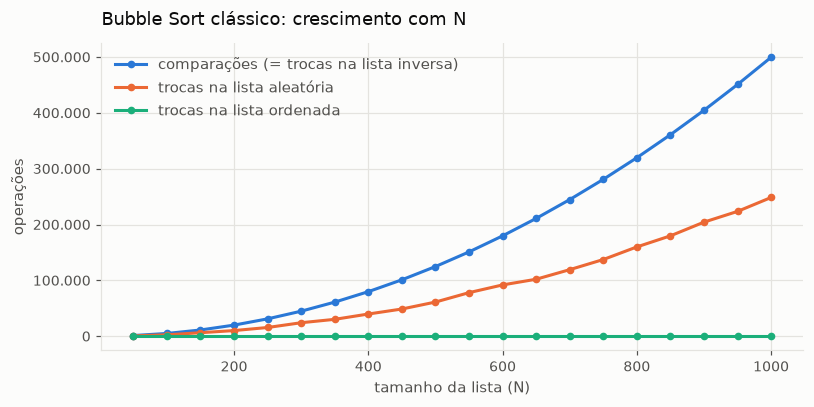

In [27]:
from apresentacao.graficos import novo, linha, mostrar, milhares, AZUL, LARANJA, VERDE
from algoritmos.metricas import medir
from algoritmos.ordenacao import bubble_sort
from dados import Cenario, lista_no_cenario

tamanhos = list(range(50, 1001, 50))
def contagem(n, cenario):
    return medir(bubble_sort, lista_no_cenario(n, cenario))[1]

comparacoes = [contagem(n, Cenario.INVERSA).comparacoes for n in tamanhos]
trocas_aleatoria = [contagem(n, Cenario.ALEATORIA).trocas for n in tamanhos]
trocas_ordenada = [contagem(n, Cenario.ORDENADA).trocas for n in tamanhos]

fig, ax = novo("Bubble Sort clássico: crescimento com N", "tamanho da lista (N)", "operações")
linha(ax, tamanhos, comparacoes, AZUL, "comparações (= trocas na lista inversa)")
linha(ax, tamanhos, trocas_aleatoria, LARANJA, "trocas na lista aleatória")
linha(ax, tamanhos, trocas_ordenada, VERDE, "trocas na lista ordenada")
milhares(ax)
mostrar(fig, ax, "ex11_crescimento_bubble")

### Resposta

| N | Comparações | Trocas (ordenada) | Trocas (aleatória) | Trocas (inversa) |
|---|---|---|---|---|
| 10 | 45 | 0 | 28 | 45 |
| 100 | 4.950 | 0 | 2.502 | 4.950 |
| 1.000 | 499.500 | 0 | 248.445 | 499.500 |

As comparações são sempre N(N−1)/2, não importa a ordem, porque essa versão faz todas as passagens.
As trocas dependem da entrada: cada troca corrige um par fora de ordem, então são 0 na lista
ordenada, iguais às comparações na inversa e perto da metade na aleatória, como previsto na Aula 5.

Quando N foi multiplicado por 10, as comparações foram multiplicadas por cerca de 100, e no gráfico
as curvas são parábolas. No pior caso, comparações mais trocas deram 90, 9.900 e 999.000, exatamente
N² − N. O crescimento é quadrático: **O(N²)**.

## Exercício 12: Bubble Sort otimizado

### Enunciado

> 1. Modifique o Bubble Sort para interromper quando não houver trocas.
> 2. Execute o algoritmo com os mesmos dados do Exercício 11.
> 3. Compare os resultados.
> 4. Analise o ganho obtido.
> 5. Relacione com Big O.

### Teoria

O pseudocódigo otimizado da Aula 3 usa uma variável `trocou`: se uma passagem inteira não fez
nenhuma troca, a lista já está ordenada. Na Aula 5 isso aparece como a diferença entre melhor caso e
pior caso de um mesmo algoritmo.

### Código

In [28]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def identidade(valor):
    return valor

def bubble_sort_com_parada(seq, chave=identidade, metricas=None, ao_fim_da_passagem=None):
    return _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas=True)

def _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas):
    metricas = metricas or Metricas()
    lista = list(seq)
    for ultimo in range(len(lista) - 1, 0, -1):     # a cada passagem, o maior restante vai para 'ultimo'
        trocou = _passagem(lista, range(ultimo), chave, metricas)
        if ao_fim_da_passagem:
            ao_fim_da_passagem(lista, metricas)
        if parar_sem_trocas and not trocou:
            break
    return lista

In [29]:
import ex12_bubble_otimizado
ex12_bubble_otimizado.main()

Exercício 12: clássico x otimizado (mesmos dados do Exercício 11)
─────────────────────────────────────────────────────────────────


N        cenário  comp. clássico  comp. otimizado  ganho  trocas (ambos)  passagens
─────  ─────────  ──────────────  ───────────────  ─────  ──────────────  ─────────
10      ordenada              45                9  80.0%               0        1/9
10     aleatória              45               45   0.0%              28        9/9
10       inversa              45               45   0.0%              45        9/9
100     ordenada           4.950               99  98.0%               0       1/99
100    aleatória           4.950            4.940   0.2%           2.502      95/99
100      inversa           4.950            4.950   0.0%           4.950      99/99
1.000   ordenada         499.500              999  99.8%               0      1/999
1.000  aleatória         499.500          499.149   0.1%         248.445    973/999
1.000    inversa         499.500          499.500   0.0%         499.500    999/999
[OK] mesma saída e mesmo número de trocas nas duas versões

ordenada: N-1 co

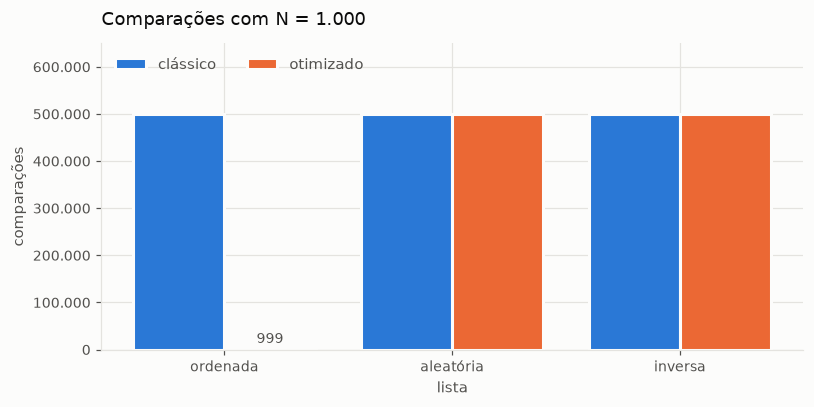

In [30]:
from apresentacao.graficos import novo, mostrar, milhares, AZUL, LARANJA, FUNDO, TEXTO_2
from algoritmos.metricas import medir
from algoritmos.ordenacao import bubble_sort, bubble_sort_com_parada
from dados import Cenario, lista_no_cenario

cenarios = list(Cenario)
classico = [medir(bubble_sort, lista_no_cenario(1000, c))[1].comparacoes for c in cenarios]
otimizado = [medir(bubble_sort_com_parada, lista_no_cenario(1000, c))[1].comparacoes for c in cenarios]

fig, ax = novo("Comparações com N = 1.000", "lista", "comparações")
pos = range(len(cenarios))
ax.bar([p - 0.2 for p in pos], classico, width=0.4, color=AZUL, edgecolor=FUNDO, linewidth=2, label="clássico")
ax.bar([p + 0.2 for p in pos], otimizado, width=0.4, color=LARANJA, edgecolor=FUNDO, linewidth=2, label="otimizado")
ax.set_xticks(list(pos), cenarios)
ax.set_ylim(0, 650000)
milhares(ax)
ax.annotate("999", (0.2, otimizado[0]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=TEXTO_2)
mostrar(fig, ax, "ex12_classico_x_otimizado", loc="upper left", ncol=2)

### Resposta

| N = 1.000 | Clássico | Otimizado | Ganho |
|---|---|---|---|
| lista ordenada | 499.500 | 999 | **99,8%** |
| lista aleatória | 499.500 | 499.149 | 0,1% |
| lista inversa | 499.500 | 499.500 | 0% |

O ganho só aparece quando a lista fica ordenada cedo. Com ela já ordenada, a primeira passagem não
troca nada e o algoritmo para depois de N − 1 comparações. Na aleatória quase não muda, porque basta
um valor pequeno perto do fim para exigir quase todas as passagens; na inversa toda passagem tem
troca. O número de trocas foi igual nas duas versões: a otimização só corta comparações inúteis.

Na Big O, o pior caso e o caso médio continuam **O(N²)**, mas o melhor caso caiu de O(N²) para
**O(N)**. Vale a pena para dados quase ordenados e não custa nada nos outros casos.

## Exercício 13: Comparação de estratégias de busca

### Enunciado

> **Parte A.** Implementar `linear_search_count(arr, target)`, `binary_search_count(sorted_arr, target)` e `bubble_sort_count(arr)`, cada uma retornando o resultado e o número de comparações. O Bubble Sort deve ordenar uma cópia.
>
> **Parte B.** Criar três listas com N = 31 (`arr_sorted`, `arr_reverse` e `arr_random` com `random.seed(42)`) e buscar o primeiro elemento, o elemento da posição N//2 e um valor ausente. Registrar as comparações da linear, da binária e, nas listas não ordenadas, do Bubble Sort e do total Bubble Sort + busca binária.
>
> **Parte C.** Escrever em Markdown: os pré-requisitos de cada busca, o Big O de cada uma, quando vale pagar o Bubble Sort para usar a binária e a relação com os resultados.

### Teoria

A Aula 2 compara a busca linear, O(N), com a binária, O(log N), e lembra que o array ordenado tem um
custo: manter a ordem. A escolha depende de quanto cada operação vai ser usada. Aqui o custo extra é
ordenar com o Bubble Sort, O(N²) (Aula 3).

### Código

In [31]:
# src/algoritmos/contagem.py
from algoritmos.busca import busca_binaria, busca_linear
from algoritmos.metricas import medir
from algoritmos.ordenacao import bubble_sort


def linear_search_count(arr, target):
    index, metricas = medir(busca_linear, arr, target)
    return index, metricas.comparacoes

def binary_search_count(sorted_arr, target):
    index, metricas = medir(busca_binaria, sorted_arr, target)
    return index, metricas.comparacoes

def bubble_sort_count(arr):
    sorted_arr, metricas = medir(bubble_sort, arr)
    return sorted_arr, metricas.comparacoes

In [32]:
import ex13_comparacao_buscas
ex13_comparacao_buscas.main()

Exercício 13: listas com N = 31
───────────────────────────────
arr_sorted   [1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31]
arr_reverse  [31 30 29 28 27 26 25 24 23 22 21 20 19 18 17 16 15 14 13 12 11 10 9 8 7 6 5 4 3 2 1]
arr_random   [20 15 11 25 28 7 6 13 12 16 10 27 31 23 17 29 2 14 19 3 18 22 30 5 26 8 9 24 1 4 21]

Comparações por lista e alvo
────────────────────────────
lista        alvo    valor  linear  binária  bubble  bubble+binária
───────────  ──────  ─────  ──────  ───────  ──────  ──────────────
arr_sorted   first       1       1        9       -               -
arr_sorted   middle     16      16        1       -               -
arr_sorted   absent     -1      31       10       -               -
arr_reverse  first      31       1        9     465             474
arr_reverse  middle     16      16        1     465             466
arr_reverse  absent     -1      31       10     465             475
arr_random   first      20       1  

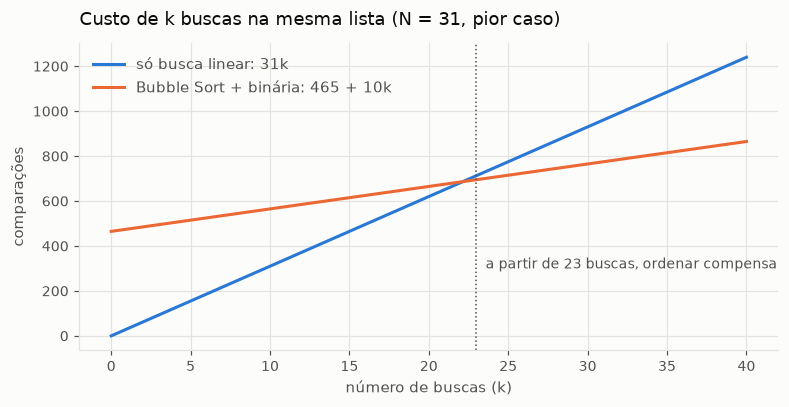

In [33]:
from apresentacao.graficos import novo, linha, mostrar, AZUL, LARANJA

buscas = list(range(0, 41))
linear = [31 * k for k in buscas]
ordenando = [465 + 10 * k for k in buscas]

fig, ax = novo("Custo de k buscas na mesma lista (N = 31, pior caso)", "número de buscas (k)", "comparações")
linha(ax, buscas, linear, AZUL, "só busca linear: 31k")
linha(ax, buscas, ordenando, LARANJA, "Bubble Sort + binária: 465 + 10k")
ax.axvline(23, color="#52514e", linewidth=1, linestyle=":")
ax.annotate("a partir de 23 buscas, ordenar compensa", (23, 300), xytext=(6, 0), textcoords="offset points", fontsize=9, color="#52514e")
mostrar(fig, ax, "ex13_ponto_de_equilibrio")

### Resposta

As três funções da Parte A ficaram em `algoritmos/contagem.py`, com os nomes e retornos do
enunciado, chamando o mesmo núcleo dos outros exercícios. Na busca binária contei duas comparações
por volta, a de igualdade com o meio e a de direção (`target < meio`), como no código do Exercício 14. Nas listas fora de
ordem, rodei o Bubble Sort antes da binária e somei o custo. A Parte C ficou em
`src/ex13_conclusao.md`:

Resultados do `ex13_comparacao_buscas.py`, com N = 31:

| Lista | Alvo | Linear | Binária | Bubble Sort | Bubble + Binária |
|---|---|---|---|---|---|
| arr_sorted | primeiro (1) | 1 | 9 | - | - |
| arr_sorted | meio (16) | 16 | 1 | - | - |
| arr_sorted | ausente (-1) | 31 | 10 | - | - |
| arr_reverse | primeiro (31) | 1 | 9 | 465 | 474 |
| arr_reverse | meio (16) | 16 | 1 | 465 | 466 |
| arr_reverse | ausente (-1) | 31 | 10 | 465 | 475 |
| arr_random | primeiro (20) | 1 | 5 | 465 | 470 |
| arr_random | meio (29) | 16 | 9 | 465 | 474 |
| arr_random | ausente (-1) | 31 | 10 | 465 | 475 |

#### 1. Pré-requisitos

A busca linear não tem pré-requisito: funciona em qualquer lista, porque olha um elemento de cada
vez. A binária exige a lista em ordem crescente, porque só assim dá para descartar uma metade
inteira olhando o meio. Testei aplicar a binária direto na `arr_random` e ela não encontrou o 20,
que está na lista.

#### 2. Big O

A linear é O(N): com o alvo ausente fez as 31 comparações. A binária é O(log N): cada volta descarta
metade da lista, então com N = 31 são no máximo 5 voltas, ou 10 comparações na minha contagem (a de
igualdade e a de direção). O Bubble Sort clássico é O(N²) e sempre faz N(N−1)/2 = 465 comparações.

#### 3. Quando vale ordenar com Bubble Sort

Para uma busca só, não vale: ordenar custa 465 comparações, e a pior busca linear custa 31. Ordenar
só compensa quando a mesma lista vai receber muitas buscas. No pior caso, k buscas custam 31k na
linear e 465 + 10k ordenando antes. A partir de **k = 23** a segunda opção fica mais barata (695
contra 713). De forma geral, com o Bubble Sort isso acontece depois de mais ou menos N/2 buscas.

#### 4. Relação com os resultados

- Com o alvo na primeira posição a linear ganhou (1 comparação contra 9 da binária). A Big O fala do
  pior caso, não de toda execução.
- Com o alvo no meio foi o contrário: a binária achou o 16 na primeira comparação e a linear precisou
  de 16.
- Com o alvo ausente, que é o pior caso das duas, foram 31 contra 10. Essa diferença cresce com N:
  para 1.000.000 de elementos seriam 1.000.000 contra 40.
- Nas listas fora de ordem, as 465 comparações do Bubble Sort dominam o total (466 a 475), muito
  mais que qualquer busca linear isolada.

Minha conclusão: se a lista já está ordenada, uso a busca binária. Se não está e vou buscar poucas
vezes, a linear sai mais barata. Ordenar antes só vale quando a mesma lista recebe muitas buscas,
mais de 23 neste caso.

## Exercício 14: Refatoração

### Enunciado

> 1. Refatore o código fornecido, preservando exatamente o comportamento.
> 2. Melhore nomes de funções, variáveis e parâmetros.
> 3. Organize o código para tornar a leitura e manutenção mais claras.
> 4. Adicione comentários técnicos objetivos.
> 5. Mantenha a complexidade assintótica dos algoritmos (busca binária e Bubble Sort).
> 6. Crie um pequeno teste que demonstre que a versão refatorada produz o mesmo resultado da original.
>
> Não usar `sorted`, `.sort()` nem bibliotecas externas, e não alterar contadores nem critérios de parada.

### Teoria

Na Aula 1, qualidade de código não é só funcionar e ser rápido: também conta a manutenibilidade, ou
seja, legibilidade e organização. Refatorar é melhorar essa parte sem mudar o que o código faz.

### Código

In [34]:
# src/algoritmos/busca.py
from algoritmos.metricas import Metricas
NAO_ENCONTRADO = -1


def busca_binaria(seq_ordenada, alvo, metricas=None, ao_inspecionar=None):
    metricas = metricas or Metricas()
    inicio, fim = 0, len(seq_ordenada) - 1
    while inicio <= fim:
        meio = (inicio + fim) // 2
        metricas.iteracoes += 1
        if ao_inspecionar:
            ao_inspecionar(inicio, fim, meio)

        metricas.comparacoes += 1
        if seq_ordenada[meio] == alvo:
            return meio

        metricas.comparacoes += 1
        if alvo < seq_ordenada[meio]:
            fim = meio - 1          # o alvo só pode estar à esquerda do meio
        else:
            inicio = meio + 1       # o alvo só pode estar à direita do meio
    return NAO_ENCONTRADO

In [35]:
# src/algoritmos/ordenacao.py
from algoritmos.metricas import Metricas


def identidade(valor):
    return valor

def bubble_sort(seq, chave=identidade, metricas=None, ao_fim_da_passagem=None):
    return _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas=False)

def _bubble(seq, chave, metricas, ao_fim_da_passagem, parar_sem_trocas):
    metricas = metricas or Metricas()
    lista = list(seq)
    for ultimo in range(len(lista) - 1, 0, -1):     # a cada passagem, o maior restante vai para 'ultimo'
        trocou = _passagem(lista, range(ultimo), chave, metricas)
        if ao_fim_da_passagem:
            ao_fim_da_passagem(lista, metricas)
        if parar_sem_trocas and not trocou:
            break
    return lista

def _passagem(lista, posicoes, chave, metricas):
    metricas.passagens += 1
    trocou = False
    for i in posicoes:
        metricas.comparacoes += 1
        if chave(lista[i]) > chave(lista[i + 1]):
            lista[i], lista[i + 1] = lista[i + 1], lista[i]
            metricas.trocas += 1
            trocou = True
    return trocou

In [36]:
# src/algoritmos/contagem.py
from algoritmos.busca import busca_binaria, busca_linear
from algoritmos.metricas import medir
from algoritmos.ordenacao import bubble_sort


def binary_search_count(sorted_arr, target):
    index, metricas = medir(busca_binaria, sorted_arr, target)
    return index, metricas.comparacoes

def bubble_sort_count(arr):
    sorted_arr, metricas = medir(bubble_sort, arr)
    return sorted_arr, metricas.comparacoes

In [37]:
import ex14_refatoracao
ex14_refatoracao.main()

binary_search_count([2, 4, 6, 8, 10, 12, 13], 8) = (3, 1)
bubble_sort_count([4, 2, 7, 1, 3])               = ([1, 2, 3, 4, 7], 10)


In [38]:
import unittest
import tests.test_ex14_refatoracao

suite = unittest.defaultTestLoader.loadTestsFromModule(tests.test_ex14_refatoracao)
resultado = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)

test_binaria_igual_ao_original (tests.test_ex14_refatoracao.TestEx14.test_binaria_igual_ao_original) ... 

ok


test_bubble_igual_ao_original (tests.test_ex14_refatoracao.TestEx14.test_bubble_igual_ao_original) ... 

ok


test_bubble_nao_altera_entrada (tests.test_ex14_refatoracao.TestEx14.test_bubble_nao_altera_entrada) ... 

ok


test_exemplos_das_aulas (tests.test_ex14_refatoracao.TestEx14.test_exemplos_das_aulas) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.085s

OK


### Resposta

| Original | Refatorado |
|---|---|
| `f(a, t)` | `busca_binaria(seq_ordenada, alvo)` + `binary_search_count` |
| `h(arr)` | `bubble_sort(seq)` + `bubble_sort_count` |
| `c`, `k` | contadores em `Metricas` (`comparacoes`) |
| `i`, `j`, `m` | `inicio`, `fim`, `meio` |
| `r` e o literal `-1` | `return` direto e a constante `NAO_ENCONTRADO` |
| `last`, `p` | `ultimo`, `i` em `_passagem` |
| troca com `tmp` | atribuição múltipla em `_passagem` |

O código refatorado virou o núcleo que os outros exercícios usam: `busca_binaria` em
`algoritmos/busca.py` e `bubble_sort` em `algoritmos/ordenacao.py`. As funções
`binary_search_count` e `bubble_sort_count` mantêm a assinatura e o retorno do original. Separei a
contagem (objeto `Metricas`) do algoritmo e tirei o `break` com variável de resultado, trocando por
`return` direto. Não mudei a lógica: as comparações são contadas nos mesmos pontos (1 pela
igualdade e mais 1 pela direção quando não acha) e os laços do Bubble Sort têm os mesmos limites,
sem parada antecipada. A complexidade continua **O(log N)** e **O(N²)**.

O teste (`src/tests/test_ex14_refatoracao.py`) tem o `f` e o `h` originais copiados sem mudança e compara
as tuplas (resultado, contador) das duas versões com `assertEqual`, em 207 listas: 7 casos de borda e
200 aleatórias com repetidos. Para a busca, ordenei cada lista com o próprio `h`, sem `sorted()`, e
procurei todos os valores presentes e mais três ausentes. Os 4 testes passaram, junto com os
15 testes do núcleo em `src/tests/test_algoritmos.py`.

## Vídeo

**Link do vídeo:** a inserir.

## Referências

- Slides das Aulas 1 a 5 da disciplina, prof. Ian Monteiro Nunes (Infnet, 2026).
- WENGROW, J. *A Common-Sense Guide to Data Structures and Algorithms*. Caps. 1 a 7.
- BHARGAVA, A. *Grokking Algorithms*. Caps. 1 e 2.
- GOODRICH, M.; TAMASSIA, R.; GOLDWASSER, M. *Data Structures and Algorithms in Python*. Caps. 1 a 3.